# A2. Simsiz aloqa kanalida signal tarqalishini modellashtirish

**Muhit:** Python + Google Colab  
**Variant:** `VARIANT = 1` qiymatini 1–15 oralig‘ida o‘zgartiring.  
**Yondashuv:** FSPL → CI → shadowing → link budget/MAPL → analitik qamrov → Monte-Carlo verifikatsiyasi → sensitivity.

## 1. Kutubxonalar va funksiyalar
Barcha hisoblashlar CPUda bajariladi; GPU talab qilinmaydi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

C0 = 299_792_458.0

def fspl_db(distance_m, frequency_hz):
    d = np.asarray(distance_m, dtype=float)
    wavelength = C0 / frequency_hz
    return 20*np.log10(4*np.pi*d/wavelength)

def ci_path_loss_mean_db(distance_m, frequency_hz, n, d0_m=1.0):
    d = np.asarray(distance_m, dtype=float)
    pl0 = fspl_db(d0_m, frequency_hz)
    return pl0 + 10*n*np.log10(d/d0_m)

def received_power_dbm(path_loss_db, pt_dbm, gt_dbi=0.0, gr_dbi=0.0, system_losses_db=0.0):
    return pt_dbm + gt_dbi + gr_dbi - system_losses_db - np.asarray(path_loss_db)

def mapl_db(pt_dbm, gt_dbi, gr_dbi, pmin_dbm, system_losses_db=0.0):
    return pt_dbm + gt_dbi + gr_dbi - system_losses_db - pmin_dbm

def coverage_probability_analytic(d, f_hz, pt_dbm, gt_dbi, gr_dbi, pmin_dbm, n, sigma_db, d0_m=1.0, system_losses_db=0.0):
    pl_mean = ci_path_loss_mean_db(d, f_hz, n, d0_m)
    pr_mean = received_power_dbm(pl_mean, pt_dbm, gt_dbi, gr_dbi, system_losses_db)
    return norm.cdf((pr_mean - pmin_dbm)/sigma_db)

def coverage_radius(p, f_hz, pt_dbm, gt_dbi, gr_dbi, pmin_dbm, n, sigma_db, d0_m=1.0, system_losses_db=0.0):
    z = norm.ppf(p)
    budget = mapl_db(pt_dbm, gt_dbi, gr_dbi, pmin_dbm, system_losses_db)
    pl0 = fspl_db(d0_m, f_hz)
    return d0_m * 10**((budget - pl0 - z*sigma_db)/(10*n))

def choose_summary_distances(d50_m, d_max_m, d_min_m=1.0):
    if d50_m <= d_max_m/1.2:
        vals = np.array([0.5*d50_m, 0.8*d50_m, d50_m, 1.2*d50_m])
    else:
        vals = np.array([0.25*d_max_m, 0.5*d_max_m, 0.75*d_max_m, d_max_m])
    return np.clip(vals, d_min_m, d_max_m)


## 2. Variant parametrlari
`n` va `sigma` qiymatlari o‘quv maqsadidagi sintetik parametrlar bo‘lib, tayyor 3GPP scenario parametrlari emas.

In [2]:
VARIANT = 1  # 1..15
variants = [[1, 3.5, 30, 2.7, 6, -92, 1500, 201], [2, 0.9, 20, 2.6, 5, -90, 1800, 202], [3, 1.8, 27, 2.8, 5, -92, 1600, 203], [4, 2.1, 30, 3.0, 7, -95, 1800, 204], [5, 2.4, 15, 2.4, 4, -85, 800, 205], [6, 2.6, 33, 2.8, 6, -96, 2000, 206], [7, 3.5, 33, 3.2, 7, -95, 1800, 207], [8, 3.7, 30, 2.5, 5, -93, 1800, 208], [9, 4.5, 30, 2.9, 6, -94, 1400, 209], [10, 5.0, 23, 2.3, 4, -90, 1000, 210], [11, 5.8, 23, 2.6, 5, -92, 900, 211], [12, 6.0, 30, 3.3, 8, -96, 1200, 212], [13, 0.7, 20, 2.7, 6, -92, 2200, 213], [14, 1.5, 30, 3.1, 7, -97, 2200, 214], [15, 3.3, 36, 2.9, 6, -98, 2500, 215]]
cols = ['variant', 'frequency_ghz', 'tx_power_dbm', 'path_loss_exponent', 'shadow_sigma_db', 'rx_sensitivity_dbm', 'd_max_m', 'seed']
variant_df = pd.DataFrame(variants, columns=cols)
row = variant_df.loc[variant_df['variant'] == VARIANT].iloc[0]
params = {
    'frequency_ghz': float(row.frequency_ghz),
    'tx_power_dbm': float(row.tx_power_dbm),
    'tx_gain_dbi': 0.0,
    'rx_gain_dbi': 0.0,
    'system_losses_db': 0.0,
    'path_loss_exponent': float(row.path_loss_exponent),
    'shadow_sigma_db': float(row.shadow_sigma_db),
    'rx_sensitivity_dbm': float(row.rx_sensitivity_dbm),
    'd0_m': 1.0, 'd_min_m': 1.0,
    'd_max_m': float(row.d_max_m),
    'n_points': 400, 'seed': int(row.seed), 'n_runs': 200
}
print(params)


{'frequency_ghz': 3.5, 'tx_power_dbm': 30.0, 'tx_gain_dbi': 0.0, 'rx_gain_dbi': 0.0, 'system_losses_db': 0.0, 'path_loss_exponent': 2.7, 'shadow_sigma_db': 6.0, 'rx_sensitivity_dbm': -92.0, 'd0_m': 1.0, 'd_min_m': 1.0, 'd_max_m': 1500.0, 'n_points': 400, 'seed': 201, 'n_runs': 200}


## 3. Bazaviy model: FSPL, CI, MAPL va qamrov radiuslari

In [3]:
f_hz = params['frequency_ghz'] * 1e9
d = np.geomspace(params['d_min_m'], params['d_max_m'], params['n_points'])
pl_d0 = fspl_db(params['d0_m'], f_hz)
fspl = fspl_db(d, f_hz)
pl_mean = ci_path_loss_mean_db(d, f_hz, params['path_loss_exponent'], params['d0_m'])
pr_mean = received_power_dbm(pl_mean, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['system_losses_db'])
MAPL = mapl_db(params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['system_losses_db'])

d50 = coverage_radius(0.50, f_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])
d90 = coverage_radius(0.90, f_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])
d95 = coverage_radius(0.95, f_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])

print(f"lambda = {C0/f_hz:.4f} m")
print(f"PL(d0=1 m) = {pl_d0:.3f} dB")
print(f"MAPL = {MAPL:.2f} dB")
print(f"d50 = {d50:.1f} m; d90 = {d90:.1f} m; d95 = {d95:.1f} m")


lambda = 0.0857 m
PL(d0=1 m) = 43.329 dB
MAPL = 122.00 dB
d50 = 819.9 m; d90 = 425.5 m; d95 = 353.4 m


## 4. Bitta shadowing realizatsiyasi va natijalar jadvali
Shadowing nuqtalari mustaqil fazoviy namuna sifatida talqin qilinadi; ular mobil terminalning uzluksiz trayektoriyasi emas.

In [4]:
rng = np.random.default_rng(params['seed'])
shadowing = rng.normal(0, params['shadow_sigma_db'], size=len(d))
pl_shadowed = pl_mean + shadowing
pr_shadowed = pr_mean - shadowing
pcov_analytic = coverage_probability_analytic(d, f_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])

df = pd.DataFrame({
    'distance_m': d, 'fspl_db': fspl, 'ci_mean_db': pl_mean,
    'shadowing_db': shadowing, 'ci_shadowed_db': pl_shadowed,
    'pr_mean_dbm': pr_mean, 'pr_shadowed_dbm': pr_shadowed,
    'analytic_pcov_pct': 100*pcov_analytic
})
display(df.head(10).round(3))
df.to_csv(f'A2v2_variant_{VARIANT:02d}_results.csv', index=False)


,distance_m,fspl_db,ci_mean_db,shadowing_db,ci_shadowed_db,pr_mean_dbm,pr_shadowed_dbm,analytic_pcov_pct
0,1.000,43.329,43.329,11.574,54.903,-13.329,-24.903,100.0
1,1.018,43.488,43.544,-3.646,39.898,-13.544,-9.898,100.0
2,1.037,43.648,43.759,-12.430,31.329,-13.759,-1.329,100.0
3,1.057,43.807,43.974,-4.806,39.168,-13.974,-9.168,100.0
4,1.076,43.966,44.189,10.361,54.550,-14.189,-24.550,100.0
5,1.096,44.125,44.404,1.695,46.098,-14.404,-16.098,100.0
6,1.116,44.284,44.619,-1.690,42.929,-14.619,-12.929,100.0
7,1.137,44.444,44.834,1.128,45.962,-14.834,-15.962,100.0
8,1.158,44.603,45.049,1.863,46.911,-15.049,-16.911,100.0
9,1.179,44.762,45.263,6.010,51.274,-15.263,-21.274,100.0


## 5. Grafiklar
`plt.title()` ishlatilmaydi; rasm nomi hisobotda rasm ostida yoziladi.

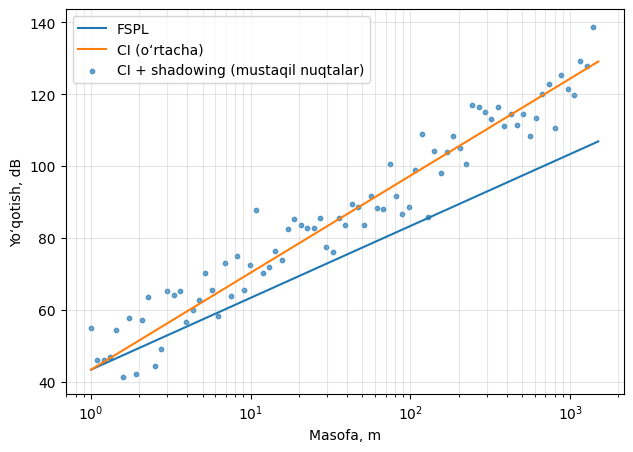

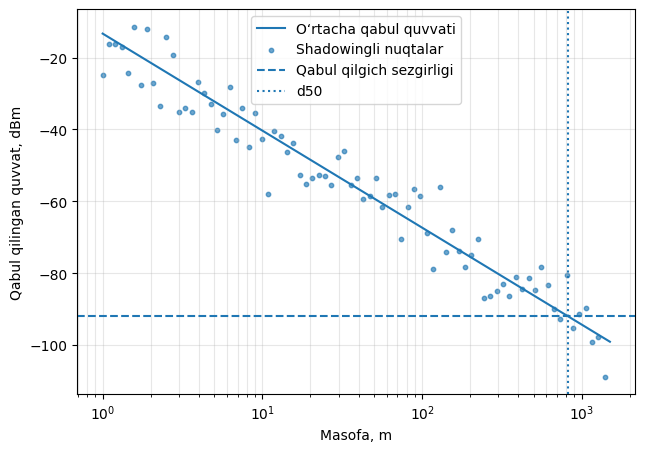

In [5]:
plt.figure(figsize=(7.2,5.0))
plt.semilogx(d, fspl, label='FSPL')
plt.semilogx(d, pl_mean, label='CI (o‘rtacha)')
plt.scatter(d[::5], pl_shadowed[::5], s=10, alpha=.65, label='CI + shadowing (mustaqil nuqtalar)')
plt.xlabel('Masofa, m'); plt.ylabel('Yo‘qotish, dB')
plt.grid(True, which='both', alpha=.3); plt.legend(); plt.show()

plt.figure(figsize=(7.2,5.0))
plt.semilogx(d, pr_mean, label='O‘rtacha qabul quvvati')
plt.scatter(d[::5], pr_shadowed[::5], s=10, alpha=.65, label='Shadowingli nuqtalar')
plt.axhline(params['rx_sensitivity_dbm'], linestyle='--', label='Qabul qilgich sezgirligi')
plt.axvline(d50, linestyle=':', label='d50')
plt.xlabel('Masofa, m'); plt.ylabel('Qabul qilingan quvvat, dBm')
plt.grid(True, which='both', alpha=.3); plt.legend(); plt.show()


## 6. Nazorat qilinadigan sensitivity-tajriba: chastotani 2 baravar oshirish
Faqat chastota o‘zgaradi. Bu real diapazon almashinuvi prognozi emas, chunki `n` va `sigma` sun’iy ravishda o‘zgarmas saqlanadi.

In [6]:
f2_hz = 2*f_hz
pl_d0_2f = fspl_db(params['d0_m'], f2_hz)
d50_2f = coverage_radius(0.50, f2_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])
d90_2f = coverage_radius(0.90, f2_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])
d95_2f = coverage_radius(0.95, f2_hz, params['tx_power_dbm'], params['tx_gain_dbi'], params['rx_gain_dbi'], params['rx_sensitivity_dbm'], params['path_loss_exponent'], params['shadow_sigma_db'])
print(f"f: {params['frequency_ghz']:.2f} -> {2*params['frequency_ghz']:.2f} GHz")
print(f"PL(d0): {pl_d0:.2f} -> {pl_d0_2f:.2f} dB, delta={pl_d0_2f-pl_d0:.2f} dB")
print(f"d50: {d50:.1f} -> {d50_2f:.1f} m")
print(f"d90: {d90:.1f} -> {d90_2f:.1f} m")
print(f"d95: {d95:.1f} -> {d95_2f:.1f} m")


f: 3.50 -> 7.00 GHz
PL(d0): 43.33 -> 49.35 dB, delta=6.02 dB
d50: 819.9 -> 490.6 m
d90: 425.5 -> 254.7 m
d95: 353.4 -> 211.5 m


## 7. Analitik qamrov ehtimolini Monte-Carlo bilan verifikatsiya qilish
200 ta realizatsiya ishlatiladi. Jadval Monte-Carlo egri chizig‘i bilan aynan bir xil realizatsiyalar matritsasidan olinadi.

In [7]:
rng_mc = np.random.default_rng(params['seed'])
shadow_runs = rng_mc.normal(0, params['shadow_sigma_db'], size=(params['n_runs'], len(d)))
pr_runs = pr_mean[None, :] - shadow_runs
pcov_mc = np.mean(pr_runs >= params['rx_sensitivity_dbm'], axis=0)

rmse_pp = 100*np.sqrt(np.mean((pcov_mc - pcov_analytic)**2))
mae_pp = 100*np.mean(np.abs(pcov_mc - pcov_analytic))
print(f"Qamrov egri chizig‘i MAE = {mae_pp:.3f} foiz punkt")
print(f"Qamrov egri chizig‘i RMSE = {rmse_pp:.3f} foiz punkt")

selected_distances = choose_summary_distances(d50, params['d_max_m'], params['d_min_m'])
rows=[]
for target_d in selected_distances:
    i = int(np.argmin(np.abs(d-target_d)))
    vals = pr_runs[:, i]
    rows.append([d[i], vals.mean(), vals.std(ddof=1), 100*pcov_analytic[i], 100*pcov_mc[i]])
summary_df = pd.DataFrame(rows, columns=['distance_m','mean_pr_dbm','std_pr_db','analytic_pcov_pct','mc_pcov_pct'])
display(summary_df.round(3))
summary_df.to_csv(f'A2v2_variant_{VARIANT:02d}_200run_summary.csv', index=False)


Qamrov egri chizig‘i MAE = 0.563 foiz punkt
Qamrov egri chizig‘i RMSE = 1.481 foiz punkt


,distance_m,mean_pr_dbm,std_pr_db,analytic_pcov_pct,mc_pcov_pct
0,408.246,-83.155,5.876,91.351,91.0
1,657.484,-88.560,5.902,66.688,72.0
2,819.232,-92.753,6.077,50.059,49.5
3,984.030,-93.811,5.927,36.065,39.5


## 8. Analitik va Monte-Carlo qamrov ehtimolini taqqoslash

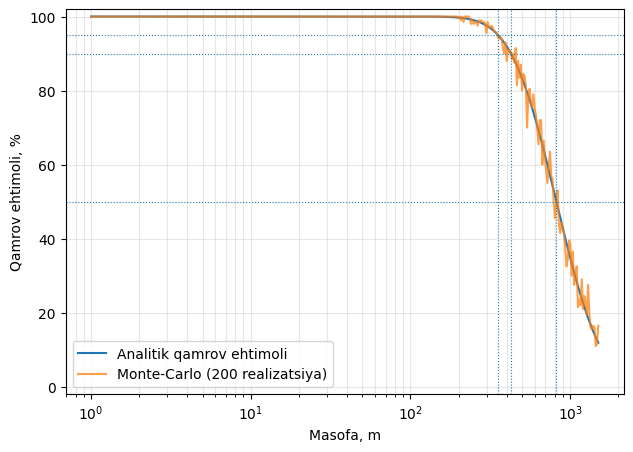

In [8]:
plt.figure(figsize=(7.2,5.0))
plt.semilogx(d, 100*pcov_analytic, label='Analitik qamrov ehtimoli')
plt.semilogx(d, 100*pcov_mc, alpha=.75, label='Monte-Carlo (200 realizatsiya)')
for y in (50, 90, 95): plt.axhline(y, linestyle=':', linewidth=.8)
for x in (d50, d90, d95): plt.axvline(x, linestyle=':', linewidth=.8)
plt.xlabel('Masofa, m'); plt.ylabel('Qamrov ehtimoli, %')
plt.ylim(-2,102); plt.grid(True, which='both', alpha=.3); plt.legend(); plt.show()


## 9. Talaba xulosasi
6–8 gapda FSPL va CI farqi, MAPL mazmuni, `n` va `sigma` ta’siri, `d50`, `d90`, `d95` farqlari, nazorat qilinadigan `f×2` tajribasi hamda analitik va Monte-Carlo egri chiziqlari mosligini izohlang.